# Data sampling

From 4.9 million Open Food Facts products to the 100_000-row sample that Laya and Jev are scored on.

Each product gets the same three questions, and Open Food Facts already holds the answers:

| Question | Type | Answer taken from |
| --- | --- | --- |
| `food_group` | `choice` | the level-1 food group |
| `ultra_processed` | `noul` (yes or no) | NOVA group 4 |
| `nutriscore` | `score` (A to E) | the Nutri-Score grade |

This notebook builds the sample step by step and checks it along the way.
Every rule is explained in more detail in [data-sampling.md](data-sampling.md).
Open it with `just lab`, or re-run it from top to bottom with `just execute`.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

assert Path(sys.prefix).resolve() == Path(".venv").resolve(), (
    f"The kernel runs {sys.executable}, not this project's .venv. Start Jupyter with `just lab`."
)

FOOD = "data/food.parquet"
SAMPLE = "data/sample.parquet"
SEED = "laya-vs-jev-2026-10-30"
SAMPLE_SIZE = 100_000
CALIBRATION_SIZE = 10_000

con = duckdb.connect()
con.execute(f"CREATE VIEW food AS SELECT * FROM '{FOOD}'")


def query(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()


def show(data: str | pd.DataFrame, precision: int = 2) -> None:
    df = query(data) if isinstance(data, str) else data
    display(df.style.hide(axis="index").format(thousands=",", precision=precision))


print(f"Python {sys.version.split()[0]} in .venv, DuckDB {duckdb.__version__}")

Python 3.13.3 in .venv, DuckDB 2.0.0


In [2]:
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
ACCENT, REST = "#2a78d6", "#b5b3aa"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 120,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10.5,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": AXIS,
    "ytick.color": AXIS,
    "xtick.labelcolor": MUTED,
    "ytick.labelcolor": INK_2,
})


def group_label(tag: str) -> str:
    return tag.removeprefix("en:").replace("-", " ")


def md_escape(text: str) -> str:
    for char in "\\`*_[]<>#|":
        text = text.replace(char, "\\" + char)
    return text


def state_card(row) -> str:
    labels = (
        f"food group **{group_label(row.food_group)}**"
        f" · ultra-processed **{'yes' if row.ultra_processed else 'no'}**"
        f" · Nutri-Score **{row.nutriscore}**"
    )
    state = "\n".join(f"> {md_escape(line)}  " for line in row.state.splitlines())
    return f"#### {md_escape(row.name)}\n\n{labels}\n\n{state}"

## 1. The raw data

The export is a single 8 GB parquet file with 111 columns.
DuckDB reads only the columns a query touches, so counting all 4.9 million products takes about a second.

In [3]:
show("SELECT count(*) AS products, count(*) FILTER (lang = 'en') AS english_products FROM food")

products,english_products
"4,884,051","2,048,669"


The three answers already sit in the data, next to the product name:

In [4]:
show("""
SELECT
    list_filter(product_name, lambda x: x.lang = 'en')[1].text AS product,
    array_to_string(food_groups_tags, ', ') AS food_groups_tags,
    nova_group,
    nutriscore_grade
FROM food
WHERE lang = 'en'
  AND len(food_groups_tags) > 0
  AND nova_group IS NOT NULL
  AND nutriscore_grade IN ('a', 'b', 'c', 'd', 'e')
LIMIT 5
""")

product,food_groups_tags,nova_group,nutriscore_grade
"Lagg's, dieter's herbal tea","en:beverages, en:unsweetened-beverages",1,b
100% Pure Canola Oil,"en:fats-and-sauces, en:fats",2,b
"Canola harvest, buttery spread, with flaxseed oil","en:fats-and-sauces, en:fats",4,d
Lithuanian Rye Bread,"en:cereals-and-potatoes, en:bread",3,e
"Bakers Best, White Bread","en:cereals-and-potatoes, en:bread",4,c


## 2. Level-1 food groups

`food_groups_tags` mixes two or three levels of the Open Food Facts taxonomy in one list, for example `en:fish-meat-eggs, en:meat, en:poultry`.
The `food_group` question only asks for level 1, the broad group.
In this export the level-1 tag is always the first element of the list.

In [5]:
show("""
SELECT food_groups_tags[1] AS level_1_group, count(*) AS products
FROM food
WHERE len(food_groups_tags) > 0
GROUP BY ALL
ORDER BY products DESC
""")

level_1_group,products
en:sugary-snacks,"307,969"
en:fish-meat-eggs,"201,156"
en:cereals-and-potatoes,"200,583"
en:milk-and-dairy-products,"184,040"
en:beverages,"165,741"
en:fats-and-sauces,"131,595"
en:fruits-and-vegetables,"108,979"
en:composite-foods,"105,227"
en:salty-snacks,"77,291"
en:alcoholic-beverages,"39,754"


Every product with a food group has exactly one level-1 tag, so taking the first element is safe:

In [6]:
con.execute("""
SET VARIABLE level1 = (
    SELECT list(DISTINCT food_groups_tags[1]) FROM food WHERE len(food_groups_tags) > 0
)
""")

show("""
SELECT
    len(list_filter(food_groups_tags, lambda t: list_contains(getvariable('level1'), t))) AS level_1_tags,
    count(*) AS products
FROM food
WHERE len(food_groups_tags) > 0
GROUP BY ALL
""")

level_1_tags,products
1,"1,527,487"


## 3. Keep the usable products

A product is usable when it is English, has an English name and ingredient list, carries all three answers, and sits in exactly one level-1 group.
`clean` strips the HTML that Open Food Facts leaves in some texts; more on that in the next section.

In [7]:
con.execute("""
CREATE OR REPLACE MACRO clean(s) AS trim(
    replace(replace(replace(
        regexp_replace(regexp_replace(s, '<[a-zA-Z/][^>]*>', '', 'g'), '&(amp;)+', '&', 'g'),
        '&quot;', '"'), '&lt;', '<'), '&gt;', '>')
)
""")

con.execute("""
CREATE OR REPLACE TABLE candidates AS
WITH en AS (
    SELECT
        code,
        clean(list_filter(product_name, lambda x: x.lang = 'en')[1].text) AS name,
        clean(list_filter(ingredients_text, lambda x: x.lang = 'en')[1].text) AS ingredients,
        food_groups_tags,
        nova_group,
        nutriscore_grade,
        nutriments
    FROM food
    WHERE lang = 'en'
      AND nova_group IS NOT NULL
      AND nutriscore_grade IN ('a', 'b', 'c', 'd', 'e')
)
SELECT *
FROM en
WHERE coalesce(name, '') <> ''
  AND coalesce(ingredients, '') <> ''
  AND len(list_filter(food_groups_tags, lambda t: list_contains(getvariable('level1'), t))) = 1
QUALIFY count(*) OVER (PARTITION BY code) = 1
""")

How each rule narrows the data, down to the 100_000 products we draw:

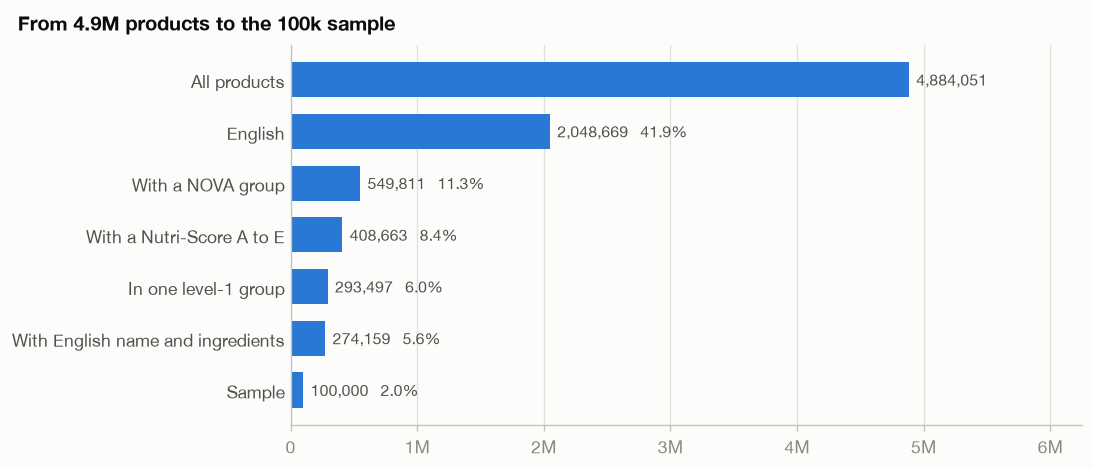

step,products
All products,"4,884,051"
English,"2,048,669"
With a NOVA group,"549,811"
With a Nutri-Score A to E,"408,663"
In one level-1 group,"293,497"
With English name and ingredients,"274,159"
Sample,"100,000"


In [8]:
funnel = query("""
SELECT
    count(*) AS "All products",
    count(*) FILTER (lang = 'en') AS "English",
    count(*) FILTER (lang = 'en' AND nova_group IS NOT NULL) AS "With a NOVA group",
    count(*) FILTER (
        lang = 'en' AND nova_group IS NOT NULL AND nutriscore_grade IN ('a', 'b', 'c', 'd', 'e')
    ) AS "With a Nutri-Score A to E",
    count(*) FILTER (
        lang = 'en' AND nova_group IS NOT NULL AND nutriscore_grade IN ('a', 'b', 'c', 'd', 'e')
        AND len(list_filter(food_groups_tags, lambda t: list_contains(getvariable('level1'), t))) = 1
    ) AS "In one level-1 group",
    (SELECT count(*) FROM candidates) AS "With English name and ingredients"
FROM food
""").iloc[0]
funnel["Sample"] = SAMPLE_SIZE

fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
ax.barh(funnel.index, funnel.values, height=0.68, color=ACCENT)
ax.invert_yaxis()
total = funnel.iloc[0]
for stage, value in funnel.items():
    share = "" if value == total else f"   {value / total:.1%}"
    ax.text(value + total * 0.012, stage, f"{value:,}{share}", va="center", color=INK_2, fontsize=9.5)
ax.set_xlim(0, total * 1.28)
ax.xaxis.set_major_formatter(lambda x, _: "0" if x == 0 else f"{x / 1e6:.0f}M")
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
fig.suptitle("From 4.9M products to the 100k sample", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.show()

show(funnel.rename("products").rename_axis("step").reset_index())

## 4. Three traps in the raw data

Three things in the data would have quietly broken the experiment.

**Answers hiding in the nutrients.**
The `nutriments` list holds two of the answers, `nova-group` and `nutrition-score-fr`, right next to fat and sugars.
Passing the whole list to the models would hand them the answers, so the state picks seven nutrients by name.
For one product:

In [9]:
show("""
WITH product AS (
    SELECT nutriments
    FROM candidates
    WHERE list_contains(list_transform(nutriments, lambda n: n.name), 'nutrition-score-fr')
      AND list_contains(list_transform(nutriments, lambda n: n.name), 'nova-group')
    ORDER BY code
    LIMIT 1
)
SELECT
    n.name AS nutrient,
    n."100g" AS value,
    CASE
        WHEN n.name IN ('nova-group', 'nutrition-score-fr') THEN 'answer, kept out'
        ELSE 'in the state'
    END AS use
FROM product, unnest(product.nutriments) AS u(n)
WHERE n.name IN ('nova-group', 'nutrition-score-fr',
                 'energy-kcal', 'fat', 'saturated-fat', 'sugars', 'salt', 'fiber', 'proteins')
ORDER BY use, nutrient
""")

nutrient,value,use
nova-group,4.00,"answer, kept out"
nutrition-score-fr,3.00,"answer, kept out"
energy-kcal,110.00,in the state
fat,8.00,in the state
fiber,62.50,in the state
proteins,26.00,in the state
salt,0.10,in the state
saturated-fat,0.10,in the state
sugars,0.60,in the state


**Salt typed in milligrams, stored in grams.**
The `unit` field is what someone typed in from the label, while the per-100 g value is always in grams.
Reading the two together would make salt look 1_000 times higher for almost half of the products.

In [10]:
show("""
SELECT name AS product, salt.value AS typed, salt.unit AS typed_unit, salt."100g" AS grams_per_100g
FROM (SELECT code, name, list_filter(nutriments, lambda n: n.name = 'salt')[1] AS salt FROM candidates)
WHERE salt.unit = 'mg' AND salt.value > 0 AND abs(salt.value / 1000 - salt."100g") < 0.001
ORDER BY code
LIMIT 3
""")

product,typed,typed_unit,grams_per_100g
"Canola harvest, buttery spread, with flaxseed oil","1,340.00",mg,1.34
Cooked Shrimp Peeled And Deveined Tail Off,560.00,mg,0.56
Shell-on shrimp,357.50,mg,0.36


**HTML inside the ingredients.**
About one ingredient list in four wraps allergens in `<span class="allergen">` tags.
They are not part of the product and cost Laya tokens out of its 512, so `clean` strips them:

In [11]:
raw = con.execute("""
SELECT list_filter(ingredients_text, lambda x: x.lang = 'en')[1].text
FROM food
WHERE lang = 'en'
  AND list_filter(ingredients_text, lambda x: x.lang = 'en')[1].text LIKE '%<span class="allergen">%'
  AND length(list_filter(ingredients_text, lambda x: x.lang = 'en')[1].text) < 160
LIMIT 1
""").fetchone()[0]
cleaned = con.execute("SELECT clean(?)", [raw]).fetchone()[0]

display(Markdown(f"As stored:\n```text\n{raw}\n```\nAfter `clean`:\n```text\n{cleaned}\n```"))

As stored:
```text
<span class="allergen">RYE FLOUR</span>, WATER, <span class="allergen">WHEAT</span>, FLOUR, MALT, MOLASSES, SUGAR, ONION, YEAST, CARAWAY SEEDS, SALT.
```
After `clean`:
```text
RYE FLOUR, WATER, WHEAT, FLOUR, MALT, MOLASSES, SUGAR, ONION, YEAST, CARAWAY SEEDS, SALT.
```

## 5. The state: what the models read

Each product becomes one short text with the name, the ingredients and seven nutrients per 100 g.
A nutrient the product does not report is left out of the text, instead of dropping the product.

In [12]:
con.execute("""
CREATE OR REPLACE MACRO num(x) AS rtrim(rtrim(printf('%.2f', x), '0'), '.')
""")

con.execute("""
CREATE OR REPLACE TABLE states AS
WITH labelled AS (
    SELECT
        code,
        name,
        ingredients,
        list_filter(nutriments, lambda n: n.name = 'energy-kcal')[1]."100g" AS energy_kcal,
        list_filter(nutriments, lambda n: n.name = 'fat')[1]."100g" AS fat,
        list_filter(nutriments, lambda n: n.name = 'saturated-fat')[1]."100g" AS saturated_fat,
        list_filter(nutriments, lambda n: n.name = 'sugars')[1]."100g" AS sugars,
        list_filter(nutriments, lambda n: n.name = 'salt')[1]."100g" AS salt,
        list_filter(nutriments, lambda n: n.name = 'fiber')[1]."100g" AS fiber,
        list_filter(nutriments, lambda n: n.name = 'proteins')[1]."100g" AS proteins,
        list_filter(food_groups_tags, lambda t: list_contains(getvariable('level1'), t))[1] AS food_group,
        nova_group = 4 AS ultra_processed,
        upper(nutriscore_grade) AS nutriscore,
        nova_group
    FROM candidates
)
SELECT
    *,
    'Product: ' || name || chr(10) ||
    'Ingredients: ' || ingredients || chr(10) ||
    'Nutrition per 100 g: ' || coalesce(nullif(concat_ws(', ',
        'energy ' || num(energy_kcal) || ' kcal',
        'fat ' || num(fat) || ' g',
        'saturated fat ' || num(saturated_fat) || ' g',
        'sugars ' || num(sugars) || ' g',
        'salt ' || num(salt) || ' g',
        'fibre ' || num(fiber) || ' g',
        'proteins ' || num(proteins) || ' g'
    ), ''), 'not reported') AS state
FROM labelled
""")

## 6. Draw the sample

Every usable product gets a fingerprint, `md5(seed || barcode)`, and the 100_000 smallest fingerprints form the sample, in fingerprint order.
That order is random but fixed: the same rows come out on every machine and with every DuckDB version.

The first 10_000 rows are the **calibration** split, used only to fit Laya's temperature.
The other 90_000 are the **evaluation** split, where every reported number comes from.

In [13]:
con.execute(f"""
CREATE OR REPLACE TABLE sample AS
SELECT
    row_number() OVER (ORDER BY md5('{SEED}' || code)) AS id,
    CASE WHEN id <= {CALIBRATION_SIZE} THEN 'calibration' ELSE 'evaluation' END AS split,
    *
FROM states
QUALIFY id <= {SAMPLE_SIZE}
ORDER BY id
""")

show("SELECT split, count(*) AS products, min(id) AS first_id, max(id) AS last_id FROM sample GROUP BY ALL ORDER BY first_id")

split,products,first_id,last_id
calibration,"10,000",1,"10,000"
evaluation,"90,000","10,001","100,000"


The first product in the sample, as both models will read it:

In [14]:
display(Markdown(state_card(next(query("SELECT * FROM sample WHERE id = 1").itertuples()))))

#### Gourmet Swiss Style Yogurt

food group **milk and dairy products** · ultra-processed **yes** · Nutri-Score **B**

> Product: Gourmet Swiss Style Yogurt  
> Ingredients: Cultured pasteurized grade a fat free milk, milk, solids, live & active cultures: bifidus, bulgaricus & thermophilus, cane sugar, mango puree, tapioca starch, pectin, vitamins & minerals added. (no preservatives).  
> Nutrition per 100 g: energy 76 kcal, fat 0 g, saturated fat 0 g, sugars 13.53 g, salt 0.14 g, fibre 0 g, proteins 3.53 g  

## 7. Health checks

The expected numbers were recorded on the export downloaded on 30 October 2026.
A ✗ means the export has changed since: write the new number down rather than forcing the old one.

In [15]:
EXPECTED = {
    "Products in the export": 4_884_051,
    "Usable products": 274_159,
    "Calibration rows": 10_000,
    "Evaluation rows": 90_000,
    "Distinct barcodes in the sample": 100_000,
    "Missing states": 0,
    "Missing at least one nutrient": 18_106,
    "No nutrition at all": 930,
    "Implausible nutrient values": 328,
    "States over 1,500 characters": 797,
}

actual = query("""
SELECT
    (SELECT count(*) FROM food) AS "Products in the export",
    (SELECT count(*) FROM candidates) AS "Usable products",
    count(*) FILTER (split = 'calibration') AS "Calibration rows",
    count(*) FILTER (split = 'evaluation') AS "Evaluation rows",
    count(DISTINCT code) AS "Distinct barcodes in the sample",
    count(*) FILTER (state IS NULL) AS "Missing states",
    count(*) FILTER (
        energy_kcal IS NULL OR fat IS NULL OR saturated_fat IS NULL OR sugars IS NULL
        OR salt IS NULL OR fiber IS NULL OR proteins IS NULL
    ) AS "Missing at least one nutrient",
    count(*) FILTER (state LIKE '%Nutrition per 100 g: not reported') AS "No nutrition at all",
    count(*) FILTER (
        list_max([fat, saturated_fat, sugars, salt, fiber, proteins]) > 100
        OR energy_kcal > 900
        OR list_min([energy_kcal, fat, saturated_fat, sugars, salt, fiber, proteins]) < 0
    ) AS "Implausible nutrient values",
    count(*) FILTER (length(state) > 1500) AS "States over 1,500 characters"
FROM sample
""").iloc[0]

checks = pd.DataFrame({
    "check": list(EXPECTED),
    "expected": list(EXPECTED.values()),
    "actual": [actual[name] for name in EXPECTED],
})
checks["ok"] = (checks.expected == checks.actual).map({True: "✓", False: "✗"})
show(checks)

check,expected,actual,ok
Products in the export,"4,884,051","4,884,051",✓
Usable products,"274,159","274,159",✓
Calibration rows,"10,000","10,000",✓
Evaluation rows,"90,000","90,000",✓
Distinct barcodes in the sample,"100,000","100,000",✓
Missing states,0,0,✓
Missing at least one nutrient,"18,106","18,106",✓
No nutrition at all,930,930,✓
Implausible nutrient values,328,328,✓
"States over 1,500 characters",797,797,✓


- The 930 products without any nutrition still have a Nutri-Score in the data.
  They stay in, with `not reported` in the state, and get their own line in the `nutriscore` analysis.
- The 328 implausible rows (more than 100 g per 100 g, more than 900 kcal, or a negative value) stay in as well.
  That is what the data says, and they may turn up as a `nutriscore` failure mode.

Laya reads at most 512 tokens.
At 3 to 4 characters per token that limit sits somewhere around 1_500 to 2_000 characters, so about 1% of the states will be cut.
The harness counts the real truncations from Laya's responses.

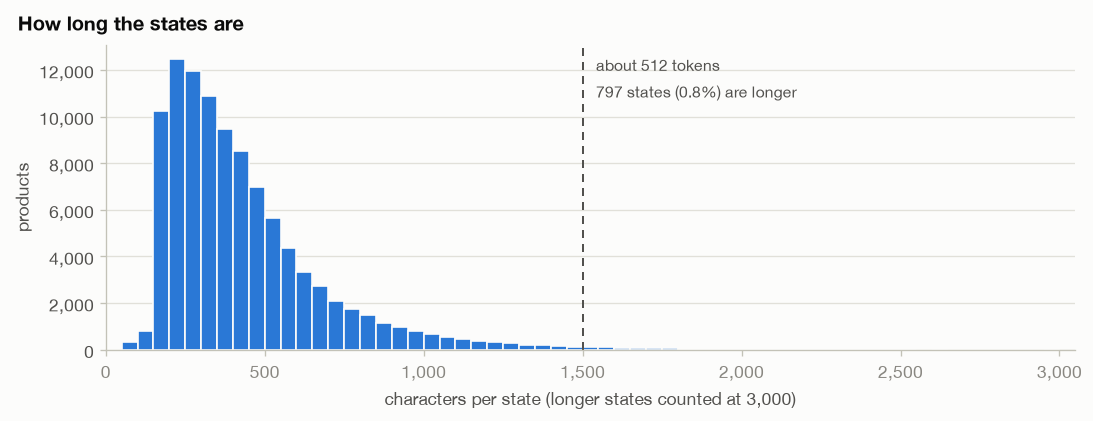

percentile,characters
50%,366
90%,756
99%,"1,425"
max,"7,367"


In [16]:
lengths = query("SELECT length(state) AS chars FROM sample").chars
longer = (lengths > 1500).sum()

fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
ax.hist(lengths.clip(upper=3000), bins=range(0, 3050, 50), color=ACCENT, edgecolor=SURFACE, linewidth=1)
ax.axvline(1500, color=INK_2, linewidth=1.2, linestyle=(0, (4, 3)))
ax.annotate(
    f"about 512 tokens\n{longer:,} states ({longer / len(lengths):.1%}) are longer",
    xy=(1500, 1), xycoords=("data", "axes fraction"),
    xytext=(8, -4), textcoords="offset points", va="top", color=INK_2, fontsize=9.5, linespacing=1.5,
)
ax.set_xlim(0, 3050)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}")
ax.set_xlabel("characters per state (longer states counted at 3,000)")
ax.set_ylabel("products")
ax.grid(axis="x", visible=False)
fig.suptitle("How long the states are", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.show()

show(
    lengths.describe(percentiles=[0.5, 0.9, 0.99]).loc[["50%", "90%", "99%", "max"]]
    .rename("characters").rename_axis("percentile").reset_index(),
    precision=0,
)

## 8. Majority baselines

A model that always gives the most common answer scores the majority baseline.
Laya and Jev have to beat it to be worth anything.
These come from the evaluation split, next to the predictions written in the README before the runs.

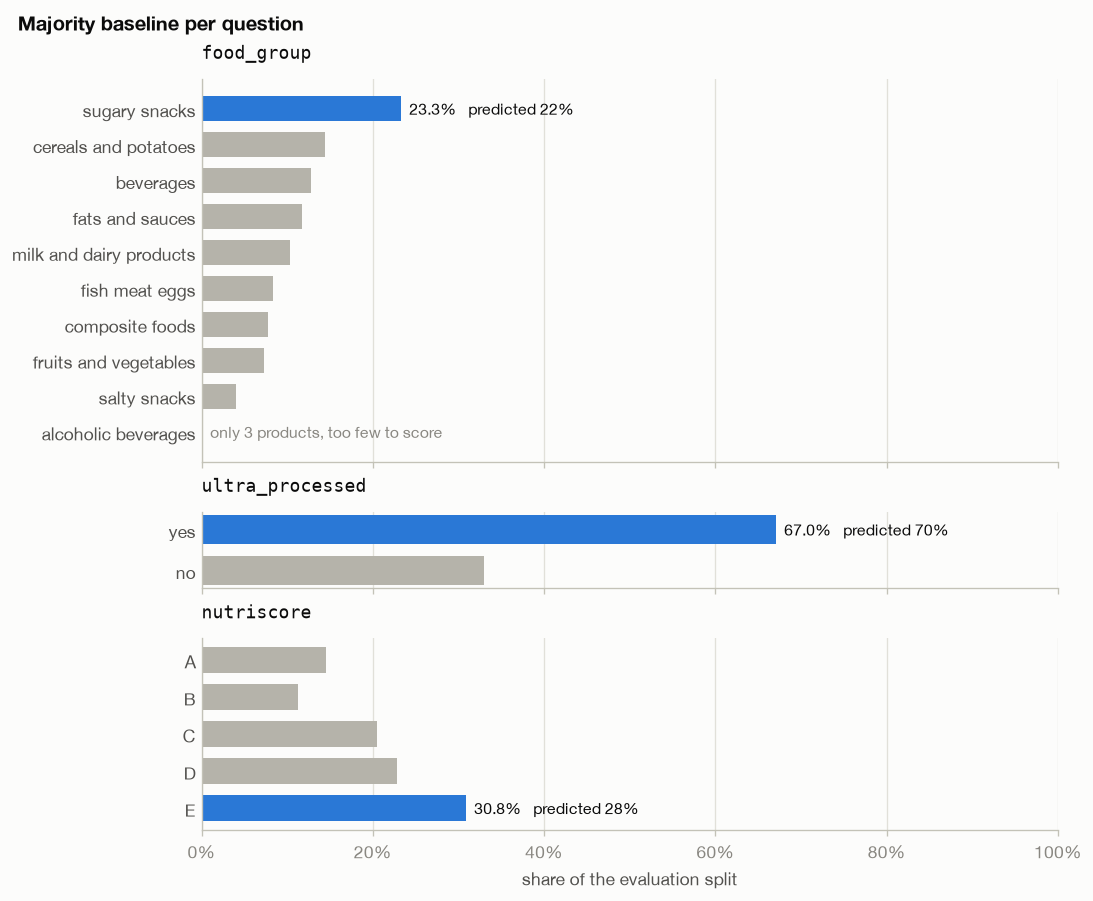

question,majority answer,baseline %,predicted %
food_group,sugary snacks,23.3,22.0
ultra_processed,yes,67.0,70.0
nutriscore,E,30.8,28.0


In [17]:
PREDICTED_BASELINE = {"food_group": 22.0, "ultra_processed": 70.0, "nutriscore": 28.0}  # README predictions


def distribution(question: str) -> pd.DataFrame:
    dist = query(f"""
        SELECT {question}::VARCHAR AS answer, count(*) AS products, 100 * count(*) / sum(count(*)) OVER () AS pct
        FROM sample
        WHERE split = 'evaluation'
        GROUP BY ALL
        ORDER BY {"answer" if question == "nutriscore" else "products DESC"}
    """)
    if question == "food_group":
        dist["answer"] = dist.answer.map(group_label)
    if question == "ultra_processed":
        dist["answer"] = dist.answer.map({"true": "yes", "false": "no"})
    return dist


distributions = {question: distribution(question) for question in PREDICTED_BASELINE}

fig, axes = plt.subplots(
    3, 1, figsize=(9, 7.4), sharex=True, layout="constrained",
    gridspec_kw={"height_ratios": [10, 2, 5]},
)
for ax, (question, dist) in zip(axes, distributions.items()):
    majority = dist.loc[dist.pct.idxmax()]
    ax.barh(dist.answer, dist.pct, height=0.7, color=[ACCENT if a == majority.answer else REST for a in dist.answer])
    ax.invert_yaxis()
    ax.text(
        majority.pct + 1, majority.answer,
        f"{majority.pct:.1f}%   predicted {PREDICTED_BASELINE[question]:.0f}%",
        va="center", color=INK, fontsize=9.5,
    )
    for answer, products, pct in dist[["answer", "products", "pct"]].itertuples(index=False):
        if products < 30:
            ax.text(pct + 1, answer, f"only {products} products, too few to score", va="center", color=MUTED, fontsize=9.5)
    ax.set_title(question, fontsize=11, fontfamily="monospace", fontweight="normal")
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
axes[-1].set_xlim(0, 100)
axes[-1].xaxis.set_major_formatter(lambda x, _: f"{x:.0f}%")
axes[-1].set_xlabel("share of the evaluation split")
fig.suptitle("Majority baseline per question", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.show()

show(
    pd.DataFrame([
        {
            "question": question,
            "majority answer": dist.loc[dist.pct.idxmax(), "answer"],
            "baseline %": dist.pct.max(),
            "predicted %": PREDICTED_BASELINE[question],
        }
        for question, dist in distributions.items()
    ]),
    precision=1,
)

Every answer, for reference:

In [18]:
show(
    pd.concat([dist.assign(question=question) for question, dist in distributions.items()])
    [["question", "answer", "products", "pct"]],
    precision=1,
)

question,answer,products,pct
food_group,sugary snacks,"20,928",23.3
food_group,cereals and potatoes,"13,005",14.4
food_group,beverages,"11,464",12.7
food_group,fats and sauces,"10,607",11.8
food_group,milk and dairy products,"9,331",10.4
food_group,fish meat eggs,"7,539",8.4
food_group,composite foods,"6,963",7.7
food_group,fruits and vegetables,"6,523",7.2
food_group,salty snacks,"3,637",4.0
food_group,alcoholic beverages,3,0.0


- `alcoholic beverages` has only 3 evaluation rows, because alcohol rarely gets a Nutri-Score.
  That is fewer than 30, so it is reported as too few rows, not removed or resampled.
- `baby foods and milks` does not survive the filter at all, so it is not one of the `food_group` options.

## 9. Read a few states by eye

Before anything goes to the models: could a person answer the three questions from these?
They come from the calibration split, so the evaluation split stays unseen until the runs.

In [19]:
for row in query("SELECT * FROM sample WHERE split = 'calibration' ORDER BY id LIMIT 5 OFFSET 1").itertuples():
    display(Markdown(state_card(row)))

#### Raspberries

food group **fruits and vegetables** · ultra-processed **no** · Nutri-Score **A**

> Product: Raspberries  
> Ingredients: RASPBERRIES.  
> Nutrition per 100 g: energy 49.2 kcal, fat 0.8 g, saturated fat 0.13 g, sugars 5.4 g, salt 0.01 g, fibre 4.3 g, proteins 1.19 g  

#### BBLUEBRA LACKCURRANT SPO& /DE NOMADIC

food group **milk and dairy products** · ultra-processed **yes** · Nutri-Score **C**

> Product: BBLUEBRA LACKCURRANT SPO& /DE NOMADIC  
> Ingredients: Low Fat Yogurt (Milk) (70.5%), Dat Cluster (28.5%): Oat Flakes, Sugar, Rapeseed Oil, Cereal Crisps (Rice Flour, Fortified Wheat Flour (Wheat Flour, Calcium Carbonate, Iron, Niacin (B3), Thiamine (B1)\], Malted Barley Flour, Sunflower Oil), Desiccated Coconut, Skimmed Milk Powder, Honey, Natural Flavouring, Freeze Dried Blackcurrant and Blueberry (1%). YOU ARE READY  
> Nutrition per 100 g: energy 173 kcal, fat 6 g, saturated fat 1.6 g, sugars 11.5 g, salt 0.08 g, fibre 2.2 g, proteins 4.7 g  

#### Italian sausage pizza

food group **composite foods** · ultra-processed **yes** · Nutri-Score **D**

> Product: Italian sausage pizza  
> Ingredients: Crust: flour, (wheat, malted barley), water, soybean oil, yeast, salt, dextrose, leavening (sodium aluminum phosphate, sodium bicarbonate), calcium propionate (preservative) and soy lecithin. cheese: pasteurized milk, pasteurized part-skim milk, cheese cultures, salt, enzymes, cellulose (anti-caking agent). sauce: tomatoes, tomato puree, (tomatoes, salt, citric acid), parmesan cheese (cultured part skim cow's milk, salt, enzymes), powdered cellulose (to prevent caking), oregano, salt, pepper. sausage: pork, water salt, natural flavorings, dextrose.  
> Nutrition per 100 g: energy 246 kcal, fat 9.23 g, saturated fat 3.85 g, sugars 1.54 g, salt 1.17 g, fibre 1.5 g, proteins 13.85 g  

#### Sunflower and Pumpkin Soft Farmhouse

food group **cereals and potatoes** · ultra-processed **yes** · Nutri-Score **A**

> Product: Sunflower and Pumpkin Soft Farmhouse  
> Ingredients: Fortified British Wheat Flour (Wheat Flour, Calcium Carbonate, Iron, Niacin, Thiamin), Water, Wholemeal British Wheat Flour, Sunflower Seeds (11%), Pumpkin Seeds (6%), Wheat Gluten, Wheat Fibre, Yeast, Wheat Bran, Fermented Wheat Flour, Salt, Oat Flakes, Rapeseed Oil, Soya Flour, Spirit Vinegar, Palm Oil, Flour Treatment Agent: Ascorbic Acid.  
> Nutrition per 100 g: energy 291 kcal, fat 10.6 g, saturated fat 1.4 g, sugars 2.5 g, salt 0.79 g, fibre 9 g, proteins 12.2 g  

#### Avocado Oil

food group **fats and sauces** · ultra-processed **no** · Nutri-Score **B**

> Product: Avocado Oil  
> Ingredients: Avocado Oil  
> Nutrition per 100 g: energy 928.57 kcal, fat 100 g, saturated fat 14.29 g, sugars 0 g, salt 0 g, fibre 0 g, proteins 0 g  

## 10. Save

In [20]:
con.execute(f"COPY sample TO '{SAMPLE}' (FORMAT parquet)")

show(f"SELECT split, count(*) AS products FROM '{SAMPLE}' GROUP BY ALL ORDER BY split")

split,products
calibration,"10,000"
evaluation,"90,000"


The sample is a derived database of Open Food Facts, under the [Open Database License](https://opendatacommons.org/licenses/odbl/1-0/).
If it is ever published, it keeps the attribution: "Data from Open Food Facts, openfoodfacts.org, available under the ODbL".